In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("Linear Regression-Student_Performance.csv")

In [3]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


Text(0, 0.5, 'Performance Index')

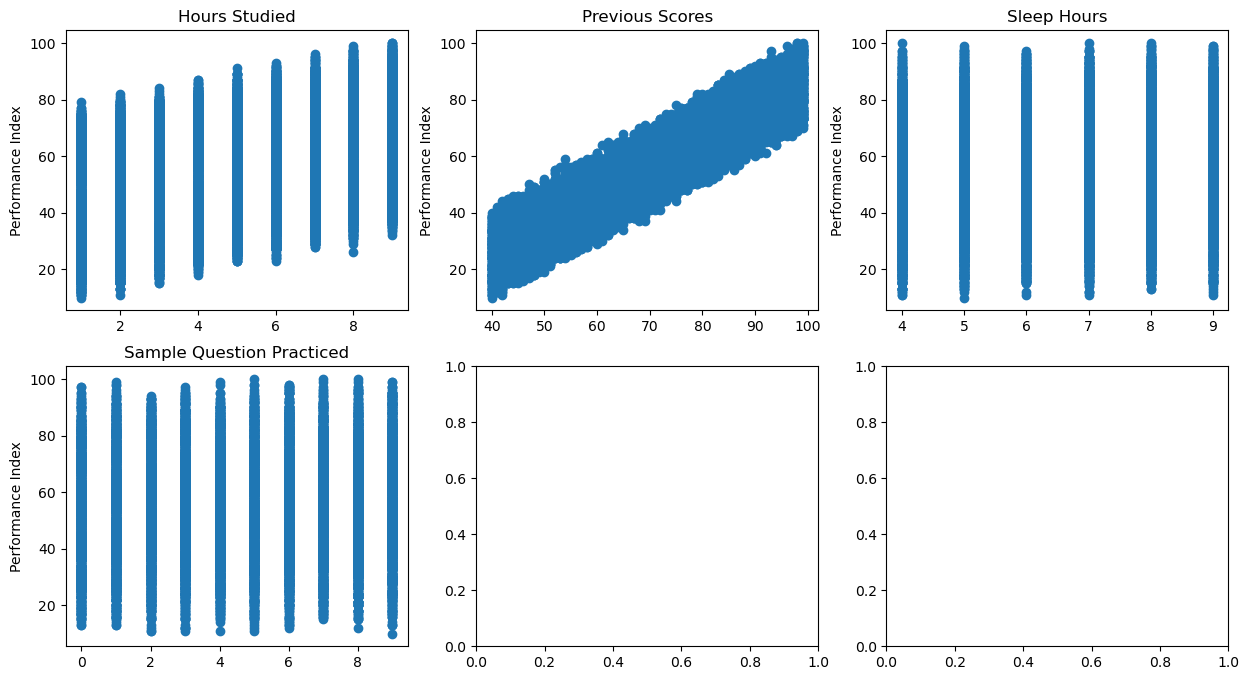

In [4]:
fig,axes=plt.subplots(nrows=2,ncols=3, figsize=(15,8))
axes[0,0].plot(df['Hours Studied'],df['Performance Index'],'o')
axes[0,0].set_title('Hours Studied')
axes[0,0].set_ylabel('Performance Index')   

axes[0,1].plot(df['Previous Scores'],df['Performance Index'],'o')
axes[0,1].set_title('Previous Scores')
axes[0,1].set_ylabel('Performance Index')  

axes[0,2].plot(df['Sleep Hours'],df['Performance Index'],'o')
axes[0,2].set_title('Sleep Hours')
axes[0,2].set_ylabel('Performance Index')

axes[1,0].plot(df['Sample Question Papers Practiced'], df['Performance Index'],'o')
axes[1,0].set_title('Sample Question Practiced')
axes[1,0].set_ylabel('Performance Index')

In [5]:
from sklearn.model_selection import train_test_split

In [6]:
X = df[[
    'Hours Studied',
    'Previous Scores',
    'Sleep Hours',
    'Sample Question Papers Practiced'
]]

y = df['Performance Index']

In [7]:
X_train,X_test, y_train, y_test=train_test_split(X,y,test_size=0.3,random_state=101)

In [8]:
from sklearn.linear_model import LinearRegression

In [9]:
model=LinearRegression()

In [10]:
model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [11]:
predictions = model.predict(X_test)

In [12]:
predictions[:10]

array([44.67439374, 95.83055254, 30.19738252, 50.05102724, 43.55917615,
       39.93160558, 77.76171263, 62.34063047, 48.84778284, 53.73152989])

In [13]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': predictions
})

comparison.head(10)

,Actual,Predicted
0,43.0,44.674394
1,95.0,95.830553
2,29.0,30.197383
3,48.0,50.051027
4,44.0,43.559176
5,40.0,39.931606
6,78.0,77.761713
7,64.0,62.340630
8,53.0,48.847783
9,56.0,53.731530


In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [15]:
MAE = mean_absolute_error(y_test, predictions)

MSE = mean_squared_error(y_test, predictions)

RMSE = np.sqrt(MSE)

R2 = r2_score(y_test, predictions)

In [16]:
print("MAE:", MAE)
print("MSE:", MSE)
print("RMSE:", RMSE)
print("R²:", R2)

MAE: 1.6284385058014377
MSE: 4.164131470832865
RMSE: 2.0406203642110565
R²: 0.9885277194859181


In [17]:
### New Linear Regression model by converting the Extracurricular Activities into a binary column######

In [18]:
df['Extracurricular Activities']=df['Extracurricular Activities'].map({'Yes':1,'No':2})

In [19]:
df['Extracurricular Activities'].head()

0    1
1    2
2    1
3    1
4    2
Name: Extracurricular Activities, dtype: int64

In [20]:
X=df[['Hours Studied','Previous Scores',
      'Extracurricular Activities','Sleep Hours',	
      'Sample Question Papers Practiced'
     ]]
y=df['Performance Index']

In [21]:
from sklearn.model_selection import train_test_split

In [22]:
from sklearn.linear_model import LinearRegression

In [23]:
X_train, X_test,y_train, y_test=train_test_split(X,y,test_size=0.3, random_state=101)

In [24]:
model=LinearRegression()

In [25]:
model.fit(X,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [26]:
New_prediction=model.predict(X_test)

In [27]:
New_prediction[:10]

array([44.4128123 , 96.15982566, 30.51820117, 49.77639092, 43.28501306,
       40.26382852, 78.10468218, 62.03324202, 48.57361303, 54.07373418])

In [28]:
New_comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': New_prediction
})

New_comparison.head(10)

,Actual,Predicted
0,43.0,44.412812
1,95.0,96.159826
2,29.0,30.518201
3,48.0,49.776391
4,44.0,43.285013
5,40.0,40.263829
6,78.0,78.104682
7,64.0,62.033242
8,53.0,48.573613
9,56.0,54.073734


In [29]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [30]:
MSE=mean_squared_error(y_test,New_prediction)
MAE=mean_absolute_error(y_test,New_prediction)
r2=r2_score(y_test,New_prediction)

In [31]:
print(f"MSE={MSE}")
print(f"MAE={MAE}")
print(f"r2={r2}")

MSE=4.084008371799158
MAE=1.6093715246368823
r2=0.9887484605154007


In [32]:
### using Keras######

In [33]:
import sys
print(sys.executable)

C:\Users\Dan\anaconda3\python.exe


In [34]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [35]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [36]:
import keras
print(keras.__version__)

3.15.0


In [37]:
import keras as ks

In [38]:
X=df[['Hours Studied','Previous Scores',
      'Extracurricular Activities','Sleep Hours',	
      'Sample Question Papers Practiced'
     ]]
y=df['Performance Index']

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=101
)

In [40]:
input=keras.Input(shape=(5,))

In [41]:
output=keras.layers.Dense(units=1)(input)

In [42]:
new_model=keras.Model(inputs=input,outputs=output)

In [43]:
new_model.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.01),
    loss='mean_squared_error'
)

In [44]:
train_history=new_model.fit(X_train,y_train,batch_size=32,epochs=20)

Epoch 1/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 68.5228  
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 32.0708
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 25.1776
Epoch 4/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 22.8560
Epoch 5/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 21.3332
Epoch 6/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 19.9143   
Epoch 7/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 18.7306  
Epoch 8/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 17.5295
Epoch 9/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 16.5360
Epoch 10/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 15.6100
Epoch 11/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 14.6273
Epoch 12/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 13.7656
Epoch 13/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 12.9909  
Epoch 14/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 12.2526
Epoch 15/20
219/219 ━━━━━━━━━━━━━━

In [45]:
Latest_predictions=new_model.predict(X_test)

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [46]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [47]:
MSE = mean_squared_error(y_test, Latest_predictions)
MAE = mean_absolute_error(y_test, Latest_predictions)
r2 = r2_score(y_test, Latest_predictions)


In [48]:
print(f"MSE={MSE}")
print(f"MAE={MAE}")
print(f"r2={r2}")

MSE=8.543801454200278
MAE=2.3289923769632974
r2=0.9764616252811054


In [49]:
from joblib import load, dump

In [50]:
final_prediction=model.fit(X,y)

In [51]:
dump(final_prediction,'final_prediction_model.joblib')

['final_prediction_model.joblib']

In [52]:
loaded_model=load('final_prediction_model.joblib')

In [53]:
loaded_model.coef_


array([ 2.85298205,  1.01843419, -0.61289758,  0.48055975,  0.19380214])

In [54]:
X.shape

(10000, 5)

In [55]:
## performance Prediction

In [56]:
New_performance = pd.DataFrame(
    [[7, 99, 1, 9, 1]],
    columns=X.columns
)

In [57]:
loaded_model.predict(New_performance)

array([91.85200884])

In [58]:
from sklearn.preprocessing import PolynomialFeatures

In [59]:
polyconveter=PolynomialFeatures(degree=2,
    interaction_only=False,
    include_bias=False,
                               )

In [60]:
converted_value=polyconveter.fit_transform(X)

In [61]:
converted_value

array([[ 7., 99.,  1., ..., 81.,  9.,  1.],
       [ 4., 82.,  2., ..., 16.,  8.,  4.],
       [ 8., 51.,  1., ..., 49., 14.,  4.],
       ...,
       [ 6., 83.,  1., ..., 64., 40., 25.],
       [ 9., 97.,  1., ..., 49.,  0.,  0.],
       [ 7., 74.,  2., ..., 64.,  8.,  1.]], shape=(10000, 20))

In [62]:
################## using the transormed data and degree 2##########

In [63]:
from sklearn.model_selection import train_test_split

In [64]:
from sklearn.linear_model import LinearRegression

In [65]:
X_train,X_test, y_train, y_test=train_test_split(converted_value,y,test_size=0.3, random_state=101)

In [66]:
model=LinearRegression()

In [67]:
model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [68]:
prediction2=model.predict(X_test)

In [69]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [70]:
MSE=mean_squared_error(y_test,prediction2)
MAE-mean_absolute_error(y_test,prediction2)
R2S=r2_score(y_test,prediction2)

print(f"MSE={MSE}")
print(f"MAE={MAE}")
print(f"R2S={R2S}")

MSE=4.0862225494059174
MAE=2.3289923769632974
R2S=0.988742360403819


In [71]:
New_residual_error=y_test-prediction2

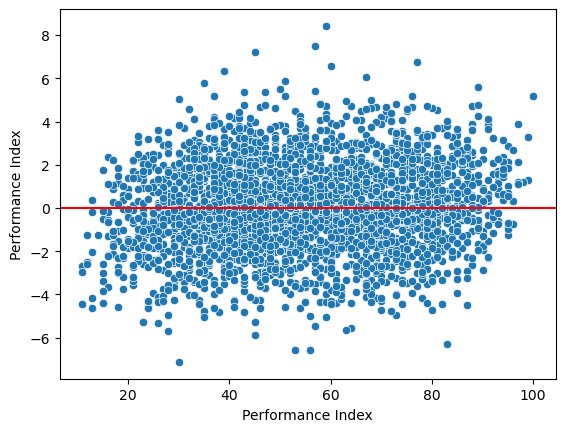

In [72]:
sns.scatterplot(x=y_test,y=New_residual_error)
plt.axhline(y=0, color='red')

In [73]:
#### using transformed data and keras####

In [74]:
from sklearn.preprocessing import PolynomialFeatures

In [75]:
transformer=PolynomialFeatures( degree=2,
    interaction_only=False,
    include_bias=False
                              )

In [76]:
converted_value=transformer.fit_transform(X)

In [77]:
converted_value.shape

(10000, 20)

In [78]:
X_train, X_test, y_train, y_test = train_test_split(
    converted_value,
    y,
    test_size=0.3,
    random_state=101
)

In [79]:
import keras

In [80]:
input=keras.Input(shape=(20,))

In [81]:
output=keras.layers.Dense(units=1)(input)

In [82]:
transofrmed_model_keras=keras.Model(inputs=input,outputs=output)

In [83]:
transofrmed_model_keras.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.01),
    loss='mean_squared_error'
)

In [84]:
transofrmed_model_keras_history=transofrmed_model_keras.fit(X_train,y_train,batch_size=32,epochs=20)

Epoch 1/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 3812.7708
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1289.4016
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1324.4948
Epoch 4/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1304.8425
Epoch 5/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1290.7329
Epoch 6/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1258.7595
Epoch 7/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1308.3506
Epoch 8/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1277.5610  
Epoch 9/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1234.9421
Epoch 10/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1314.8026
Epoch 11/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1264.1138
Epoch 12/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1292.1516
Epoch 13/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1267.4966
Epoch 14/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1283.9556
Epoch 15/20
2

In [85]:
transformed_data_keras_prediction=transofrmed_model_keras.predict(X_test)

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [86]:
MSE = mean_squared_error(y_test, transformed_data_keras_prediction)
MAE = mean_absolute_error(y_test, transformed_data_keras_prediction)
r2 = r2_score(y_test, transformed_data_keras_prediction)

print(f"MSE={MSE}")
print(f"MAE={MAE}")
print(f"R2={r2}")

MSE=639.2489772972734
MAE=23.11032107671102
R2=-0.7611460246300696


In [87]:
import os
os.getcwd()

'C:\\Users\\Dan\\Desktop\\Realted to ML and AI-Actual\\kaggle exercise\\datasets & solutions\\Linear Rgression'